# Recommender Systems: Collaborative Filtering

Have you ever wondered how Netflix or Amazon knows exactly what to suggest to you? They use Recommender Systems.

Instead of relying on a pre-built library that hides all the magic, we are going to build a **User-Based Collaborative Filtering** system entirely from scratch using pure Linear Algebra (Numpy). This is exactly how the math works under the hood.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('ggplot')

## 1. The User-Item Ratings Matrix
We start with a matrix. Rows represent Users, and Columns represent Items (like movies). 
A `0` means the user hasn't seen the movie yet. Our goal is to predict what rating they *would* give the `0`s!

In [2]:
# 5 Users, 5 Movies. 0 = Unrated.
ratings = np.array([
    [5, 4, 1, 0, 0],   # User 1 loves the first two movies
    [4, 5, 2, 1, 0],   # User 2 is very similar to User 1
    [1, 1, 5, 4, 4],   # User 3 loves the last three movies
    [0, 1, 4, 5, 5],   # User 4 is very similar to User 3
    [0, 0, 5, 4, 5]    # User 5 also loves the last three movies
])

users = [f'User {i}' for i in range(1, 6)]
movies = [f'Movie {i}' for i in range(1, 6)]

df_ratings = pd.DataFrame(ratings, index=users, columns=movies)
print("Raw Ratings Matrix:")
display(df_ratings)

Raw Ratings Matrix:


,Movie 1,Movie 2,Movie 3,Movie 4,Movie 5
User 1,5,4,1,0,0
User 2,4,5,2,1,0
User 3,1,1,5,4,4
User 4,0,1,4,5,5
User 5,0,0,5,4,5


## 2. Calculating Cosine Similarity
To figure out who is similar to who, we calculate the angle between their rating vectors. 
- If the angle is 0, the cosine is `1.0` (They have identical tastes).
- If the angle is 90 degrees, the cosine is `0.0` (They have nothing in common).

In [3]:
def compute_cosine_similarity(matrix):
    # L2 Norm (Euclidean length) of each user's vector
    norm = np.linalg.norm(matrix, axis=1, keepdims=True)
    # Normalize the matrix to prevent division by zero
    normalized_matrix = matrix / (norm + 1e-9)
    # The dot product of normalized vectors yields the cosine similarity!
    return np.dot(normalized_matrix, normalized_matrix.T)

sim_matrix = compute_cosine_similarity(ratings)
sim_df = pd.DataFrame(sim_matrix, index=users, columns=users)

print("Cosine Similarity Matrix:")
display(sim_df.round(2))

Cosine Similarity Matrix:


,User 1,User 2,User 3,User 4,User 5
User 1,1.00,0.96,0.28,0.15,0.09
User 2,0.96,1.00,0.44,0.32,0.25
User 3,0.28,0.44,1.00,0.97,0.98
User 4,0.15,0.32,0.97,1.00,0.98
User 5,0.09,0.25,0.98,0.98,1.00


## 3. Visualizing Taste Clusters
Let's map this out in a heatmap. You should easily be able to see that Users 1 & 2 form a "taste cluster", while Users 3, 4, & 5 form a separate cluster.

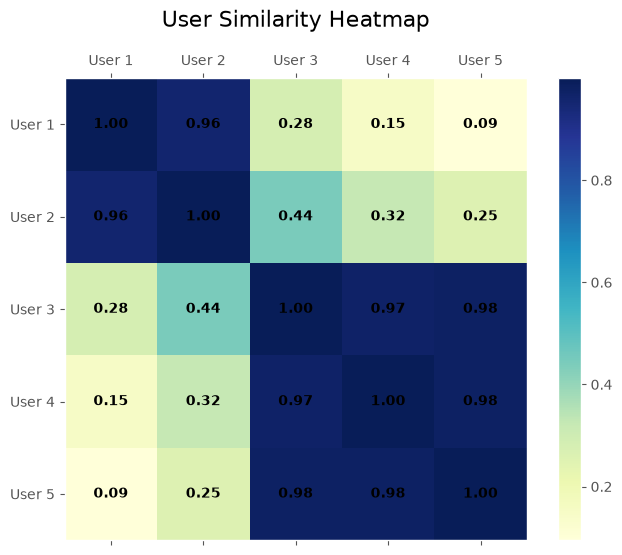

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(sim_df.values, cmap='YlGnBu')
plt.colorbar(cax)

ax.set_xticks(range(len(users)))
ax.set_yticks(range(len(users)))
ax.set_xticklabels(users)
ax.set_yticklabels(users)

# Inject the exact similarity numbers into the grid
for (i, j), val in np.ndenumerate(sim_matrix):
    ax.text(j, i, f'{val:.2f}', ha='center', va='center', color='black', weight='bold')

plt.title('User Similarity Heatmap', pad=20, fontsize=16)
plt.grid(False)
plt.show()

## 4. Making the Recommendation
Now for the magic. User 1 hasn't seen Movie 4 (`Rating = 0`). Should we recommend it to them?
We can predict their rating by taking a weighted average of how *other similar users* rated Movie 4.

In [5]:
target_user_idx = 0  # User 1
target_movie_idx = 3 # Movie 4

# Get similarity scores between User 1 and everyone else
user_similarities = sim_matrix[target_user_idx]

# Get how everyone else rated Movie 4
movie_ratings = ratings[:, target_movie_idx]

# Calculate the weighted average (ignoring User 1's own 0 rating)
weighted_sum = 0
similarity_sum = 0

for i in range(1, len(users)):
    if movie_ratings[i] > 0:  # Only count users who actually watched the movie
        weighted_sum += user_similarities[i] * movie_ratings[i]
        similarity_sum += user_similarities[i]

predicted_rating = weighted_sum / similarity_sum if similarity_sum > 0 else 0

print(f"User 1 is predicted to rate Movie 4 a {predicted_rating:.2f} out of 5.")
print("Since the predicted rating is low, we should NOT recommend Movie 4 to User 1!")

User 1 is predicted to rate Movie 4 a 2.17 out of 5.
Since the predicted rating is low, we should NOT recommend Movie 4 to User 1!
